# Check for the way of combining predictions in ensemble_6 (5 models), ensemble_4 (6 models), ensemble_5 (7 models) 

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from adbench.myutils import Utils
import sklearn.metrics as skm

2026-04-19 13:34:17.038784: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-04-19 13:34:17.066673: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-04-19 13:34:17.596696: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
/usr/lib/python3/dist-packages/requests/__init__.py:87: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (4.0.0) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({}) doesn't match a supported "


In [2]:
ensemble_6_dir = "../results/adbench/ensemble_6/train_seed=0"
ensemble_4_dir = "../results/adbench/ensemble_4/train_seed=0"
ensemble_5_dir = "../results/adbench/ensemble_5/train_seed=0"

In [3]:
def low_density_anomalies(test_log_probs, num_anomalies):
    """ Helper function for the F1-score, selects the num_anomalies lowest values of test_log_prob
    """
    anomaly_indices = np.argpartition(test_log_probs, num_anomalies - 1)[:num_anomalies]
    preds = np.zeros(len(test_log_probs))
    preds[anomaly_indices] = 1
    return preds

In [4]:
seed = 0
utils = Utils()  # utils function
utils.set_seed(seed)

## 1. ensemble_6

#### 1. For the situation that we compute the ensemble `average score per sample`

In [5]:
average_ensemble_6_aucroc_scores = []
average_ensemble_6_aucpr_scores = []
average_ensemble_6_f1_scores = []
datasets_name = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_6_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']

        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble average score per sample
        avg_score = np.mean(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-avg_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(avg_score))
        avg_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=avg_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        average_ensemble_6_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        average_ensemble_6_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        average_ensemble_6_f1_scores.append(f1)


# compute average scores of all datasets
average_ensemble_6_avg_aucroc = round(sum(average_ensemble_6_aucroc_scores) / len(average_ensemble_6_aucroc_scores), 4)
average_ensemble_6_avg_aucpr = round(sum(average_ensemble_6_aucpr_scores) / len(average_ensemble_6_aucpr_scores), 4)
average_ensemble_6_avg_f1 = round(sum(average_ensemble_6_f1_scores) / len(average_ensemble_6_f1_scores), 4)

print(f"number of datasets: {len(average_ensemble_6_aucroc_scores)}")
print(f"Average aucroc: {average_ensemble_6_avg_aucroc}")
print(f"Average aucpr: {average_ensemble_6_avg_aucpr}")
print(f"Average f1: {average_ensemble_6_avg_f1}")


number of datasets: 121
Average aucroc: 0.7645
Average aucpr: 0.4821
Average f1: 0.4684


In [6]:
# create data
# number_base_models = [6 for i in range(0, len(datasets_name))]
# average_dict = {'#base_models': number_base_models, 'datasets_name': datasets_name, 'aucroc': average_ensemble_aucroc_scores, 'aucpr':average_ensemble_aucpr_scores, 'f1': average_ensemble_f1_scores}
# average_df = pd.DataFrame(average_dict)
# average_df

#### 2. For the situation that we compute the ensemble `max score per sample`

In [7]:
max_ensemble_6_aucroc_scores = []
max_ensemble_6_aucpr_scores = []
max_ensemble_6_f1_scores = []
datasets_name = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_6_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']
        
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble max score per sample
        max_score = np.max(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-max_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(max_score))
        max_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=max_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        max_ensemble_6_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        max_ensemble_6_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        max_ensemble_6_f1_scores.append(f1)



# compute average scores of all datasets
max_ensemble_6_avg_aucroc = round(sum(max_ensemble_6_aucroc_scores) / len(max_ensemble_6_aucroc_scores), 4)
max_ensemble_6_avg_aucpr = round(sum(max_ensemble_6_aucpr_scores) / len(max_ensemble_6_aucpr_scores), 4)
max_ensemble_6_avg_f1 = round(sum(max_ensemble_6_f1_scores) / len(max_ensemble_6_f1_scores), 4)

print(f"number of datasets: {len(max_ensemble_6_aucroc_scores)}")
print(f"Average aucroc: {max_ensemble_6_avg_aucroc}")
print(f"Average aucpr: {max_ensemble_6_avg_aucpr}")
print(f"Average f1: {max_ensemble_6_avg_f1}")


number of datasets: 121
Average aucroc: 0.754
Average aucpr: 0.4692
Average f1: 0.4561


### 3. For the situation that we compute the ensemble `min score per sample`

In [8]:
min_ensemble_6_aucroc_scores = []
min_ensemble_6_aucpr_scores = []
min_ensemble_6_f1_scores = []
datasets_name = []

# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_6_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']

        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble min score per sample
        min_score = np.min(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-min_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(min_score))
        min_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=min_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        min_ensemble_6_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        min_ensemble_6_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        min_ensemble_6_f1_scores.append(f1)


# compute average scores of all datasets
min_ensemble_6_avg_aucroc = round(sum(min_ensemble_6_aucroc_scores) / len(min_ensemble_6_aucroc_scores), 4)
min_ensemble_6_avg_aucpr = round(sum(min_ensemble_6_aucpr_scores) / len(min_ensemble_6_aucpr_scores), 4)
min_ensemble_6_avg_f1 = round(sum(min_ensemble_6_f1_scores) / len(min_ensemble_6_f1_scores), 4)

print(f"number of datasets: {len(min_ensemble_6_aucroc_scores)}")
print(f"Average aucroc: {min_ensemble_6_avg_aucroc}")
print(f"Average aucpr: {min_ensemble_6_avg_aucpr}")
print(f"Average f1: {min_ensemble_6_avg_f1}")


number of datasets: 121
Average aucroc: 0.7446
Average aucpr: 0.4595
Average f1: 0.4466


## 2. ensemble_4

#### mean

In [9]:
average_ensemble_4_aucroc_scores = []
average_ensemble_4_aucpr_scores = []
average_ensemble_4_f1_scores = []
datasets_name = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_4_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']

        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble average score per sample
        avg_score = np.mean(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-avg_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(avg_score))
        avg_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=avg_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        average_ensemble_4_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        average_ensemble_4_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        average_ensemble_4_f1_scores.append(f1)


# compute average scores of all datasets
average_ensemble_4_avg_aucroc = round(sum(average_ensemble_4_aucroc_scores) / len(average_ensemble_4_aucroc_scores), 4)
average_ensemble_4_avg_aucpr = round(sum(average_ensemble_4_aucpr_scores) / len(average_ensemble_4_aucpr_scores), 4)
average_ensemble_4_avg_f1 = round(sum(average_ensemble_4_f1_scores) / len(average_ensemble_4_f1_scores), 4)

print(f"number of datasets: {len(average_ensemble_4_aucroc_scores)}")
print(f"Average aucroc: {average_ensemble_4_avg_aucroc}")
print(f"Average aucpr: {average_ensemble_4_avg_aucpr}")
print(f"Average f1: {average_ensemble_4_avg_f1}")


number of datasets: 121
Average aucroc: 0.7652
Average aucpr: 0.484
Average f1: 0.4718


#### max

In [10]:
max_ensemble_4_aucroc_scores = []
max_ensemble_4_aucpr_scores = []
max_ensemble_4_f1_scores = []
datasets_name = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_4_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']
        
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble max score per sample
        max_score = np.max(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-max_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(max_score))
        max_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=max_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        max_ensemble_4_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        max_ensemble_4_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        max_ensemble_4_f1_scores.append(f1)



# compute average scores of all datasets
max_ensemble_4_avg_aucroc = round(sum(max_ensemble_4_aucroc_scores) / len(max_ensemble_4_aucroc_scores), 4)
max_ensemble_4_avg_aucpr = round(sum(max_ensemble_4_aucpr_scores) / len(max_ensemble_4_aucpr_scores), 4)
max_ensemble_4_avg_f1 = round(sum(max_ensemble_4_f1_scores) / len(max_ensemble_4_f1_scores), 4)

print(f"number of datasets: {len(max_ensemble_4_aucroc_scores)}")
print(f"Average aucroc: {max_ensemble_4_avg_aucroc}")
print(f"Average aucpr: {max_ensemble_4_avg_aucpr}")
print(f"Average f1: {max_ensemble_4_avg_f1}")


number of datasets: 121
Average aucroc: 0.7506
Average aucpr: 0.4698
Average f1: 0.4598


#### min

In [11]:
min_ensemble_4_aucroc_scores = []
min_ensemble_4_aucpr_scores = []
min_ensemble_4_f1_scores = []
datasets_name = []

# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_4_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']

        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble min score per sample
        min_score = np.min(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-min_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(min_score))
        min_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=min_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        min_ensemble_4_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        min_ensemble_4_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        min_ensemble_4_f1_scores.append(f1)


# compute average scores of all datasets
min_ensemble_4_avg_aucroc = round(sum(min_ensemble_4_aucroc_scores) / len(min_ensemble_4_aucroc_scores), 4)
min_ensemble_4_avg_aucpr = round(sum(min_ensemble_4_aucpr_scores) / len(min_ensemble_4_aucpr_scores), 4)
min_ensemble_4_avg_f1 = round(sum(min_ensemble_4_f1_scores) / len(min_ensemble_4_f1_scores), 4)

print(f"number of datasets: {len(min_ensemble_4_aucroc_scores)}")
print(f"Average aucroc: {min_ensemble_4_avg_aucroc}")
print(f"Average aucpr: {min_ensemble_4_avg_aucpr}")
print(f"Average f1: {min_ensemble_4_avg_f1}")


number of datasets: 121
Average aucroc: 0.7552
Average aucpr: 0.4667
Average f1: 0.4532


## 3. ensemble_5

#### mean

In [12]:
average_ensemble_5_aucroc_scores = []
average_ensemble_5_aucpr_scores = []
average_ensemble_5_f1_scores = []
datasets_name = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_5_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']

        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble average score per sample
        avg_score = np.mean(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-avg_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(avg_score))
        avg_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=avg_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        average_ensemble_5_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        average_ensemble_5_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        average_ensemble_5_f1_scores.append(f1)


# compute average scores of all datasets
average_ensemble_5_avg_aucroc = round(sum(average_ensemble_5_aucroc_scores) / len(average_ensemble_5_aucroc_scores), 4)
average_ensemble_5_avg_aucpr = round(sum(average_ensemble_5_aucpr_scores) / len(average_ensemble_5_aucpr_scores), 4)
average_ensemble_5_avg_f1 = round(sum(average_ensemble_5_f1_scores) / len(average_ensemble_5_f1_scores), 4)

print(f"number of datasets: {len(average_ensemble_5_aucroc_scores)}")
print(f"Average aucroc: {average_ensemble_5_avg_aucroc}")
print(f"Average aucpr: {average_ensemble_5_avg_aucpr}")
print(f"Average f1: {average_ensemble_5_avg_f1}")


number of datasets: 121
Average aucroc: 0.7696
Average aucpr: 0.4884
Average f1: 0.4773


#### max

In [13]:
max_ensemble_5_aucroc_scores = []
max_ensemble_5_aucpr_scores = []
max_ensemble_5_f1_scores = []
datasets_name = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_5_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']
        
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble max score per sample
        max_score = np.max(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-max_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(max_score))
        max_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=max_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        max_ensemble_5_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        max_ensemble_5_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        max_ensemble_5_f1_scores.append(f1)



# compute average scores of all datasets
max_ensemble_5_avg_aucroc = round(sum(max_ensemble_5_aucroc_scores) / len(max_ensemble_5_aucroc_scores), 4)
max_ensemble_5_avg_aucpr = round(sum(max_ensemble_5_aucpr_scores) / len(max_ensemble_5_aucpr_scores), 4)
max_ensemble_5_avg_f1 = round(sum(max_ensemble_5_f1_scores) / len(max_ensemble_5_f1_scores), 4)

print(f"number of datasets: {len(max_ensemble_5_aucroc_scores)}")
print(f"Average aucroc: {max_ensemble_5_avg_aucroc}")
print(f"Average aucpr: {max_ensemble_5_avg_aucpr}")
print(f"Average f1: {max_ensemble_5_avg_f1}")


number of datasets: 121
Average aucroc: 0.7507
Average aucpr: 0.4708
Average f1: 0.4621


#### min

In [14]:
min_ensemble_5_aucroc_scores = []
min_ensemble_5_aucpr_scores = []
min_ensemble_5_f1_scores = []
datasets_name = []

# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_5_dir):
    if "all_scores_seed0.npz" in files:
        file_path = os.path.join(subdir, "all_scores_seed0.npz")
        df = np.load(file_path)
        all_scores = df['all_scores']
        labels = df['labels']

        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # compute the ensemble min score per sample
        min_score = np.min(all_scores, axis=0)

        # following DTE:
        indices = np.arange(len(labels))
        p = low_density_anomalies(-min_score, len(indices[labels == 1]))
        f1_score = skm.f1_score(labels, p)
        inds = np.where(np.isnan(min_score))
        min_score[inds] = 0
        result = utils.metric(y_true=labels, y_score=min_score)
        result = {seed: {'aucroc': result['aucroc'], 'aucpr': result['aucpr'], 'f1': f1_score,
                         'time-per-inst': 0,
                         'context-len': 0}}
        df = pd.DataFrame(result)

        # Transpose the DataFrame to match the desired structure
        df = df.transpose().reset_index()
        df.columns = ['seed', 'aucroc', 'aucpr', 'f1', 'time-per-inst', 'context-len']


        # extract scores
        aucroc = df['aucroc'].values[0]
        min_ensemble_5_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        min_ensemble_5_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        min_ensemble_5_f1_scores.append(f1)


# compute average scores of all datasets
min_ensemble_5_avg_aucroc = round(sum(min_ensemble_5_aucroc_scores) / len(min_ensemble_5_aucroc_scores), 4)
min_ensemble_5_avg_aucpr = round(sum(min_ensemble_5_aucpr_scores) / len(min_ensemble_5_aucpr_scores), 4)
min_ensemble_5_avg_f1 = round(sum(min_ensemble_5_f1_scores) / len(min_ensemble_5_f1_scores), 4)

print(f"number of datasets: {len(min_ensemble_5_aucroc_scores)}")
print(f"Average aucroc: {min_ensemble_5_avg_aucroc}")
print(f"Average aucpr: {min_ensemble_5_avg_aucpr}")
print(f"Average f1: {min_ensemble_5_avg_f1}")


number of datasets: 121
Average aucroc: 0.7525
Average aucpr: 0.4628
Average f1: 0.4518


### Visualization

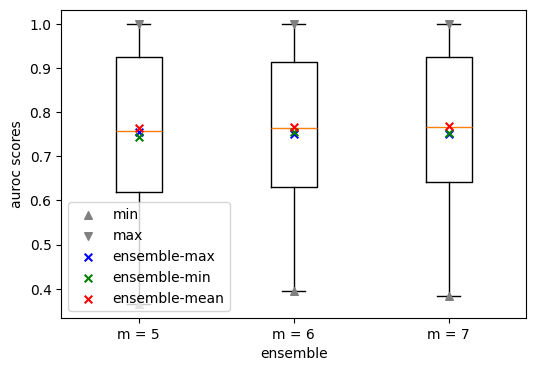

In [18]:
ensembles_auroc = [average_ensemble_6_aucroc_scores, average_ensemble_4_aucroc_scores, average_ensemble_5_aucroc_scores]

positions = [1, 2, 3]
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(ensembles_auroc)
#sns.stripplot(data=ensembles_auroc, color='black', alpha=0.5)


ensemble_mean = [average_ensemble_6_avg_aucroc, average_ensemble_4_avg_aucroc, average_ensemble_5_avg_aucroc]
ensemble_max = [max_ensemble_6_avg_aucroc, max_ensemble_4_avg_aucroc, max_ensemble_5_avg_aucroc]
ensemble_min = [min_ensemble_6_avg_aucroc, min_ensemble_4_avg_aucroc, min_ensemble_5_avg_aucroc]


# add markers
for x, arr, me, ma, mi in zip(positions, ensembles_auroc, ensemble_mean, ensemble_max, ensemble_min):
    # mean
    ax.scatter(x, np.min(arr), marker="^", color="gray", s=30, zorder=3, label="min" if x == 1 else "")
    ax.scatter(x, np.max(arr), marker="v", color="gray", s=30, zorder=3, label="max" if x == 1 else "")
    ax.scatter(x, ma, marker="x", color="blue", s=30, zorder=3, label="ensemble-max" if x == 1 else "")
    ax.scatter(x, mi, marker="x", color="green", s=30, zorder=3, label="ensemble-min" if x == 1 else "")
    ax.scatter(x, me, marker="x", color="red", s=30, zorder=3, label="ensemble-mean" if x == 1 else "")

ax.set_xticklabels(['m = 5', 'm = 6', 'm = 7'])
plt.xlabel('ensemble')
plt.ylabel('auroc scores')
ax.legend()
#plt.savefig('compare_auroc_combination_functions.png', dpi=300, bbox_inches='tight')
plt.show()